# Yield analysis: recorded data, imputation and comparison
Each row represents one **province, species, year and quarter**. Yield is measured in metric tons. The data have already been cleaned.

| Part | Data used | Question |
|---|---|---|
| Missingness | Original dataset, including blanks | Where are yields missing? |
| EDA and statistical tests | Recorded yields only; original environmental measurements | What patterns exist in the measured data? |
| Imputation | Recorded yields for fitting and validation | Which simple method should fill eligible blanks? |
| After-imputation comparison | Recorded and estimated yields, clearly labelled | How much do summaries and model coefficients change? |

**Recorded** means present in the original file. **Imputed** means estimated. Main EDA never treats estimates as measurements. Run all cells in order; only the completed-data CSV is exported.

## 1. Setup
Change the file path or validation settings here. `REPEATS = 3` runs three trials for each gap pattern.

**Terms used in this notebook:**
- **Recorded yield:** a value present in the original dataset, including a recorded zero.
- **Missing yield:** a blank value that has not been recorded.
- **Province-species combination:** one species in one province, such as sardines in CDO. Code calls its observations over time a `series`.
- **Imputed yield:** an estimated value used to fill a blank.

Keep `ALLOW_ALL_MISSING_SERIES = False`. This leaves a combination unfilled if none of its yields have ever been recorded.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display, Markdown
DATA_PATH = Path('blueshift_dataset.csv')
OUTPUT_DIR = Path('analysis_outputs')

SEED = 42
REPEATS = 3
ALPHA = 0.05
ALLOW_ALL_MISSING_SERIES = False
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 15)

def interpret(text):
    display(Markdown(text))

def adjust_pvalues(table, p='p'):
    table = table.copy()
    valid = table[p].notna()
    table.loc[valid, 'q_BH'] = multipletests(table.loc[valid, p], method='fdr_bh')[1]
    return table
versions = {m: __import__(m).__version__ for m in [
    'numpy',
    'pandas',
    'scipy',
    'statsmodels',
    'seaborn',
]}
print(platform.python_version(), versions)

3.14.2 {'numpy': '2.4.1', 'pandas': '2.3.3', 'scipy': '1.17.0', 'statsmodels': '0.14.6', 'seaborn': '0.13.2'}


## 2. Load and check the data
Check that each province-species-year-quarter row occurs only once, that the other variables have no blanks, and that recorded yields are not negative. No additional cleaning is applied.

Code uses `chl` for chlorophyll concentration and `sst` for sea surface temperature. These measurements are repeated for every species in the same province and quarter. Count each environmental measurement only once when summarizing it.

In [2]:
source_data = pd.read_csv(DATA_PATH)
rename = {column: column.lower() for column in source_data.columns}
for column in source_data.columns:
    if column.startswith('Chlorophyll'):
        rename[column] = 'chl'
    elif column.startswith('Sea Surface'):
        rename[column] = 'sst'
    elif column.startswith('Yield'):
        rename[column] = 'yield'
data = source_data.rename(columns=rename).copy()
TARGET = 'yield'
data['quarter_n'] = data.quarter.str.extract('(\\d+)')[0].astype(int)
data['time'] = (data.year - data.year.min()) * 4 + data.quarter_n - 1
data['series'] = data.province + ' | ' + data.species
data['missing'] = data[TARGET].isna().astype(int)
assert not data.duplicated(['year', 'quarter', 'province', 'species']).any(), 'Duplicate panel keys: inspect before continuing'
assert data[['year', 'quarter', 'province', 'species', 'chl', 'sst']].notna().all().all()
assert data.loc[data[TARGET].notna(), TARGET].ge(0).all()
environmental_data = data.drop_duplicates(['province', 'time']).copy()
assert data.groupby(['province', 'time'])[['chl', 'sst']].nunique().max().max() == 1
observed_data = data[data[TARGET].notna()].copy()
observed_data['log_y'] = np.log1p(observed_data[TARGET])
observed_per_series = data.groupby('series')[TARGET].count()
data['series_observed_n'] = data.series.map(observed_per_series)

## 3. Understand missing yield

### 3.1 How much is missing?
A blank yield means **unknown**, not zero. Recorded zeros remain real observations. Count missing values in every column before choosing an imputation method.

In [3]:
missing_summary = pd.DataFrame({
    'Missing values': source_data.isna().sum(),
    'Missing (%)': source_data.isna().mean() * 100,
})
display(missing_summary.round(1))
interpret(f'**{data[TARGET].isna().sum():,} of {len(data):,} yields are missing '
          f'({data["missing"].mean():.1%}).**')

,Missing values,Missing (%)
Year,0,0.0
Quarter,0,0.0
Province,0,0.0
Species,0,0.0
Chlorophyll-A Concentration (mg/m³),0,0.0
Sea Surface Temperature (°C),0,0.0
Yield (Metric Tons),62618,41.2


**62,618 of 152,064 yields are missing (41.2%).**

### 3.2 Where are the gaps?
Compare missing percentages by year, province and species. For province and species, show the ten highest percentages. This identifies groups with poor reporting coverage.

In [4]:
def missing_by_group(column):
    counts = data.groupby(column)[TARGET].agg(total='size', observed='count')
    counts['missing'] = counts['total'] - counts['observed']
    counts['missing_pct'] = 100 * counts['missing'] / counts['total']
    return counts

for column in ['year', 'province', 'species']:
    summary = missing_by_group(column)
    if column != 'year':
        summary = summary.sort_values('missing_pct', ascending=False).head(10)
    interpret(f'**Missing yield by {column}**')
    display(summary.round(1))
interpret('**Reading these tables:** missing_pct compares missing yields with all rows in each group. '
          'High percentages identify limited data coverage, not necessarily low production. '
          'Year-to-year differences can reflect reporting changes. Province and species tables show only the ten highest percentages.')

**Missing yield by year**

,total,observed,missing,missing_pct
year,,,,
2002,3168,1441,1727,54.5
2003,6336,3043,3293,52.0
2004,6336,3299,3037,47.9
2005,6336,3577,2759,43.5
2006,6336,3677,2659,42.0
2007,6336,3726,2610,41.2
2008,6336,3778,2558,40.4
2009,6336,3769,2567,40.5
2010,6336,3763,2573,40.6


**Missing yield by province**

,total,observed,missing,missing_pct
province,,,,
Davao Occidental,6336,903,5433,85.7
Dinagat Islands,6336,1634,4702,74.2
Lanao del Sur,6336,2432,3904,61.6
Camiguin,6336,2961,3375,53.3
Sulu,6336,3051,3285,51.8
Tawi-Tawi,6336,3131,3205,50.6
Sarangani,6336,3243,3093,48.8
Davao del Sur,6336,3486,2850,45.0
Basilan,6336,3557,2779,43.9


**Missing yield by species**

,total,observed,missing,missing_pct
species,,,,
Sardines,2304,51,2253,97.8
Mussel,2304,104,2200,95.5
Ludong Mullet,2304,124,2180,94.6
Starry Goby,2304,220,2084,90.5
Spiny Lobster,2304,278,2026,87.9
Spade Fish,2304,317,1987,86.2
Other Crustaceans,2304,321,1983,86.1
Climbing Perch,2304,355,1949,84.6
Tarpon,2304,424,1880,81.6


**Reading these tables:** missing_pct compares missing yields with all rows in each group. High percentages identify limited data coverage, not necessarily low production. Year-to-year differences can reflect reporting changes. Province and species tables show only the ten highest percentages.

### 3.3 Which province-species combinations have no recorded yield?
Consider sardines in CDO across all years and quarters:

| Situation | Example | What we do |
|---|---|---|
| Some yields are recorded and others are missing | Q1 = 10, Q2 = 20, Q3 = missing, Q4 = 30 | Estimate the missing yield using the selected method and its available data |
| Every yield is missing across all years and quarters | No recorded sardine yield for CDO anywhere in the dataset | Leave the yields blank in the completed-yield column |

For the first example, the same-year quarterly mean is (10 + 20 + 30) / 3 = **20 metric tons**.

For the second situation, we cannot tell whether the species was absent or its yield was simply not reported. **No recorded yield does not mean zero yield.** The default rule therefore leaves these combinations unfilled. Any model suggestion is stored separately and is not treated as a completed yield.

In [5]:
never_observed = data['series_observed_n'].eq(0)
eligible_gap = data[TARGET].isna() & ~never_observed
coverage = pd.DataFrame({
    'Category': ['Recorded yield', 'Missing yield in a combination with recorded data', 'Combinations with no recorded yield'],
    'Rows': [data[TARGET].notna().sum(), eligible_gap.sum(), never_observed.sum()],
})
display(coverage)
interpret(f'**{observed_per_series.eq(0).sum()} province-species combinations have no recorded yield.** '
          f'Leave their {never_observed.sum():,} rows unresolved by default; '
          f'{eligible_gap.sum():,} other gaps are eligible for imputation.')
interpret('**Decision:** the middle row is eligible for filling. The last row remains blank in yield_completed. '
          'Model suggestions for the last row are kept separately and are not treated as measured yields.')

,Category,Rows
0,Recorded yield,89446
1,Missing yield in a combination with recorded data,42170
2,Combinations with no recorded yield,20448


**213 province-species combinations have no recorded yield.** Leave their 20,448 rows unresolved by default; 42,170 other gaps are eligible for imputation.

**Decision:** the middle row is eligible for filling. The last row remains blank in yield_completed. Model suggestions for the last row are kept separately and are not treated as measured yields.

### 3.4 Is missingness associated with a group?
The chi-square test asks: **is the missing-yield proportion the same across the groups of this variable?**

- **p:** a small value suggests different missing percentages.
- **q_BH:** p adjusted for the four tests; use 0.05 as the cutoff.
- **Cramer's V:** association strength, from 0 (weak) to 1 (strong).

These are screening tests because observations repeat over time. They do not explain why yields are missing or prove that imputation is unbiased. Very small p-values may display as zero due to numerical precision.

In [6]:
def test_missingness(column):
    # Each row is a group; columns count observed and missing yields.
    counts = pd.crosstab(data[column], data['missing'])
    chi_square, p_value, degrees_freedom, expected = stats.chi2_contingency(counts)
    # Cramer's V simplifies because this table has two columns.
    strength = np.sqrt(chi_square / counts.to_numpy().sum())
    return {
        'variable': column,
        'chi_square': chi_square,
        'df': degrees_freedom,
        'p': p_value,
        'cramers_v': strength,
        'smallest_expected_count': expected.min(),
    }

missing_tests = pd.DataFrame([
    test_missingness(column)
    for column in ['year', 'quarter', 'province', 'species']
])
missing_tests = adjust_pvalues(missing_tests)
display(missing_tests)
strongest = missing_tests.sort_values('cramers_v', ascending=False).iloc[0]
interpret(f'Missingness is most strongly associated with **{strongest.variable}** '
          f'(strength = {strongest.cramers_v:.2f}). '
          'Compare group-aware methods with the overall median. '
          'Validation on known yields may not represent missing yields.')

,variable,chi_square,df,p,cramers_v,smallest_expected_count,q_BH
0,year,929.454755,24,8.315140e-181,0.078181,1304.541667,1.108685e-180
1,quarter,10.624794,3,1.393781e-02,0.008359,15654.500000,1.393781e-02
2,province,15870.795299,23,0.000000e+00,0.323062,2609.083333,0.000000e+00
3,species,58722.055692,65,0.000000e+00,0.621423,948.757576,0.000000e+00


Missingness is most strongly associated with **species** (strength = 0.62). Compare group-aware methods with the overall median. Validation on known yields may not represent missing yields.

### 3.5 Visual summary
Each cell is one species-province combination. Dark cells have fewer missing yields; light cells have more. A value of 1 means every yield is missing.

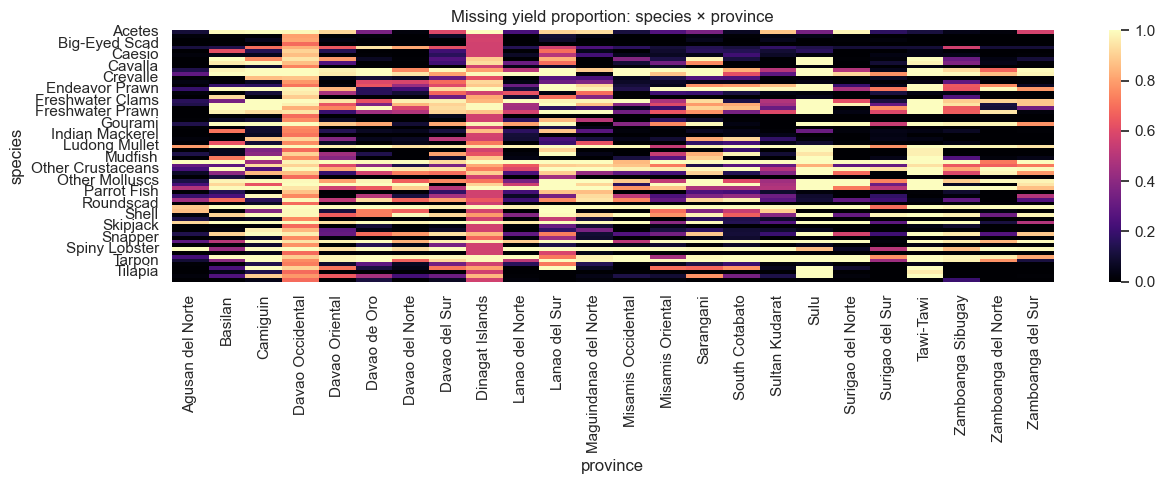

**Heatmap interpretation:** 213 combinations have every yield missing. The mix of dark and light bands shows uneven coverage across species and provinces. Light cells indicate missing information; they do not indicate zero catch.

In [7]:
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(
    data.pivot_table(index='species', columns='province', values='missing'),
    vmin=0,
    vmax=1,
    cmap='magma',
    ax=ax,
)
ax.set_title('Missing yield proportion: species × province')
plt.tight_layout()
plt.show()
interpret(f'**Heatmap interpretation:** {observed_per_series.eq(0).sum()} combinations have every yield missing. '
          'The mix of dark and light bands shows uneven coverage across species and provinces. '
          'Light cells indicate missing information; they do not indicate zero catch.')

## 4. EDA: recorded data only
**No imputed yields are used in this section.** All yield summaries, plots and tests use rows with recorded yield (`observed_data`). Environmental summaries count each province-quarter measurement once (`environmental_data`).

The order is: individual distributions, relationships between two variables, then an adjusted model with multiple predictors. Results describe associations in the available records, not causal effects or complete population production.

### 4.1 Univariate EDA: one variable at a time
#### Summary tables
The median describes a typical recorded yield. The mean is more sensitive to large yields. Environmental summaries use one measurement per province and quarter.

In [8]:
display(observed_data[TARGET].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame('observed_yield'))
display(environmental_data[['chl', 'sst']].describe().T)

interpret(f'**Yield summary:** median = {observed_data[TARGET].median():,.2f}, '
          f'mean = {observed_data[TARGET].mean():,.2f}, '
          f'99th percentile = {observed_data[TARGET].quantile(.99):,.2f} metric tons. '
          'The mean is much higher than the median, showing that a small number of large yields strongly affect averages and totals.')
interpret(f'**Environmental summary:** mean chlorophyll = {environmental_data.chl.mean():.3f} mg/m3; '
          f'mean sea temperature = {environmental_data.sst.mean():.2f} C. '
          'These describe available province-quarter conditions, not independent measurements for every species.')

,observed_yield
count,89446.000000
mean,473.399010
std,4431.622177
min,0.000000
1%,0.020000
25%,3.350000
50%,23.880000
75%,142.460000
95%,1051.455000
99%,5206.490000


,count,mean,std,min,25%,50%,75%,max
chl,2304.0,0.578815,0.427815,0.09411,0.251518,0.519027,0.733136,4.136375
sst,2304.0,29.733587,0.791915,26.41099,29.354220,29.846079,30.279936,31.696978


**Yield summary:** median = 23.88, mean = 473.40, 99th percentile = 5,206.49 metric tons. The mean is much higher than the median, showing that a small number of large yields strongly affect averages and totals.

**Environmental summary:** mean chlorophyll = 0.579 mg/m3; mean sea temperature = 29.73 C. These describe available province-quarter conditions, not independent measurements for every species.

#### Distribution tests
The normality test asks whether values follow a bell-shaped normal distribution. `q_BH` adjusts for the four tests. Skewness measures asymmetry; excess kurtosis describes tail weight. Repeated observations make the p-values diagnostic screens, so use the plots too.

In [9]:
rows = []
for name, values in [
    ('yield', observed_data[TARGET]),
    ('log1p_yield', observed_data.log_y),
    ('chl', environmental_data.chl),
    ('sst', environmental_data.sst),
]:
    k, p = stats.normaltest(values)
    rows.append(dict(
        variable=name,
        n=len(values),
        skew=stats.skew(values),
        excess_kurtosis=stats.kurtosis(values),
        normality_K2=k,
        p=p,
    ))
normal = adjust_pvalues(pd.DataFrame(rows))
display(normal)

rejected = normal.loc[normal.q_BH < ALPHA, 'variable'].tolist()
interpret(f'**Normality check:** departures are flagged for {", ".join(rejected) or "none"} at q < {ALPHA}. '
          'A log transformation can improve readability without making yields normally distributed. '
          'Rejection is not a reason to delete valid observations.')

,variable,n,skew,excess_kurtosis,normality_K2,p,q_BH
0,yield,89446,24.637894,804.847837,213562.699098,0.000000e+00,0.000000e+00
1,log1p_yield,89446,0.384241,-0.417043,3112.778364,0.000000e+00,0.000000e+00
2,chl,2304,2.412435,10.024873,1255.394775,2.480209e-273,3.306945e-273
3,sst,2304,-0.856367,0.956392,259.807376,3.833055e-57,3.833055e-57


**Normality check:** departures are flagged for yield, log1p_yield, chl, sst at q < 0.05. A log transformation can improve readability without making yields normally distributed. Rejection is not a reason to delete valid observations.

#### Distribution plots
The first four panels show distributions. The Q-Q plot compares recorded log yield with a normal distribution: departures from the straight line indicate non-normal shape. The quarter bar chart counts dataset rows, not production.

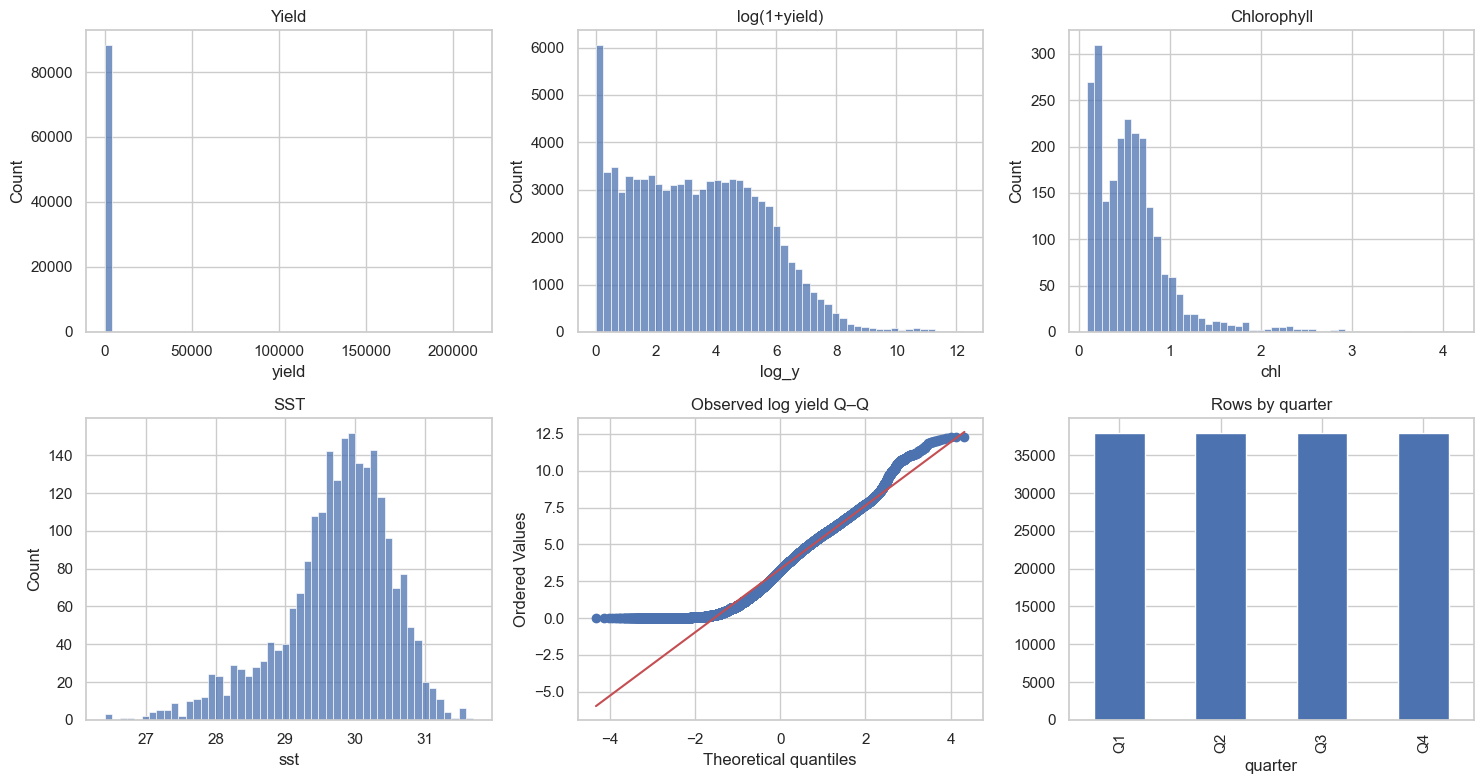

**Yield histogram:** the long right tail means most yields are relatively small, with a few very large values. **Log-yield histogram:** compressing the upper tail makes typical differences easier to see; values are now log(1 + metric tons).

**Chlorophyll histogram:** skewness = 2.41; higher values form a right tail. **Temperature histogram:** the middle 50% lies between 29.35 and 30.28 C. These plots describe conditions, not their effects on yield.

**Q-Q plot:** curved tails show that log yield still departs from a normal distribution. **Quarter counts:** equal row counts reflect the layout of the dataset; they do not establish equal yield or equal reporting completeness.

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, values) in zip(
    axes.flat,
    [
        ('Yield', observed_data[TARGET]),
        ('log(1+yield)', observed_data.log_y),
        ('Chlorophyll', environmental_data.chl),
        ('SST', environmental_data.sst),
    ],
):
    sns.histplot(values, bins=50, ax=ax)
    ax.set_title(name)
stats.probplot(observed_data.log_y, plot=axes[1, 1])
axes[1, 1].set_title('Observed log yield Q–Q')
data.groupby('quarter').size().reindex(['Q1', 'Q2', 'Q3', 'Q4']).plot.bar(ax=axes[1, 2], title='Rows by quarter')
plt.tight_layout()
plt.show()

interpret('**Yield histogram:** the long right tail means most yields are relatively small, with a few very large values. '
          '**Log-yield histogram:** compressing the upper tail makes typical differences easier to see; values are now log(1 + metric tons).')
interpret(f'**Chlorophyll histogram:** skewness = {stats.skew(environmental_data.chl):.2f}; higher values form a right tail. '
          f'**Temperature histogram:** the middle 50% lies between {environmental_data.sst.quantile(.25):.2f} '
          f'and {environmental_data.sst.quantile(.75):.2f} C. '
          'These plots describe conditions, not their effects on yield.')
interpret('**Q-Q plot:** curved tails show that log yield still departs from a normal distribution. '
          '**Quarter counts:** equal row counts reflect the layout of the dataset; they do not establish equal yield or equal reporting completeness.')

### 4.2 Bivariate EDA: two variables at a time
#### Unadjusted relationship tests
Spearman correlation ranges from -1 to 1: the sign gives direction and magnitude gives strength. Kruskal-Wallis tests for distribution differences across groups. Its reported effect is an approximate epsilon-squared measure, not a correlation. Ordinary p-values assume independent rows; these are screening results.

In [11]:
rows = []
for x in ['chl', 'sst', 'year']:
    rho, p = stats.spearmanr(observed_data[x], observed_data[TARGET])
    rows.append(dict(predictor=x, test='Spearman (iid screen)', effect=rho, p=p))
for x in ['province', 'species', 'quarter']:
    groups = [v[TARGET].to_numpy() for _, v in observed_data.groupby(x)]
    h, p = stats.kruskal(*groups)
    rows.append(dict(
        predictor=x,
        test='Kruskal (iid screen)',
        effect=max(0, (h - len(groups) + 1) / (len(observed_data) - len(groups))),
        p=p,
    ))
bivariate_screen = adjust_pvalues(pd.DataFrame(rows))
display(bivariate_screen)

for _, result in bivariate_screen[bivariate_screen.test.str.startswith('Spearman')].iterrows():
    direction = 'positive' if result.effect > 0 else 'negative' if result.effect < 0 else 'zero'
    interpret(f'**{result.predictor} and yield:** Spearman rho = {result.effect:.3f} ({direction}), '
              f'q = {result.q_BH:.3g}. A small q-value can accompany a weak relationship in a large dataset.')
interpret('**Group tests:** a small Kruskal-Wallis q-value suggests that at least some groups have different yield distributions. '
          'It does not identify the differing pairs or show that the grouping variable causes the difference.')

,predictor,test,effect,p,q_BH
0,chl,Spearman (iid screen),0.048958,1.331497e-48,1.997246e-48
1,sst,Spearman (iid screen),0.040904,1.943444e-34,2.332133e-34
2,year,Spearman (iid screen),-0.084512,1.906903e-141,3.813807e-141
3,province,Kruskal (iid screen),0.193141,0.000000e+00,0.000000e+00
4,species,Kruskal (iid screen),0.374283,0.000000e+00,0.000000e+00
5,quarter,Kruskal (iid screen),0.000211,6.812398e-05,6.812398e-05


**chl and yield:** Spearman rho = 0.049 (positive), q = 2e-48. A small q-value can accompany a weak relationship in a large dataset.

**sst and yield:** Spearman rho = 0.041 (positive), q = 2.33e-34. A small q-value can accompany a weak relationship in a large dataset.

**year and yield:** Spearman rho = -0.085 (negative), q = 3.81e-141. A small q-value can accompany a weak relationship in a large dataset.

**Group tests:** a small Kruskal-Wallis q-value suggests that at least some groups have different yield distributions. It does not identify the differing pairs or show that the grouping variable causes the difference.

#### Relationship between the environmental variables
Use unique province-quarter records so the same environmental measurement is not counted once for every species.

In [12]:
rho, p = stats.spearmanr(environmental_data.chl, environmental_data.sst)
interpret(f'Environment-only Spearman correlation: rho={rho:.3f}, nominal p={p:.3g}; repeated provinces still induce dependence.')

interpret('**Interpretation:** the correlation describes how chlorophyll and temperature move together. '
          'It is not a yield relationship, and repeated measurements within provinces limit ordinary p-value interpretation.')

Environment-only Spearman correlation: rho=0.112, nominal p=7.64e-08; repeated provinces still induce dependence.

**Interpretation:** the correlation describes how chlorophyll and temperature move together. It is not a yield relationship, and repeated measurements within provinces limit ordinary p-value interpretation.

#### Tests allowing repeated measurements
Fit one predictor at a time and allow observations for the same province-species combination to be related over time. These tests still do not adjust for the other predictors. `r2` is the fraction of recorded log-yield variation explained by each one-predictor model.

In [13]:
rows = []
for x in ['chl', 'sst', 'year', 'province', 'species', 'quarter']:
    term = f'C({x})' if x in ['province', 'species', 'quarter'] else x
    fit = smf.ols('log_y ~ ' + term, observed_data).fit(
        cov_type='cluster',
        cov_kwds={'groups': observed_data.series},
        use_t=True,
    )
    w = fit.wald_test_terms(scalar=True).table.loc[term]
    rows.append(dict(predictor=x, F=float(w.statistic), p=float(w.pvalue), r2=fit.rsquared))
biv = adjust_pvalues(pd.DataFrame(rows))
display(biv)

significant = biv.loc[biv.q_BH < ALPHA, 'predictor'].tolist()
interpret(f'**Repeated-measurement tests:** {", ".join(significant) or "none"} meet q < {ALPHA}. '
          'Compare r2 with significance: a statistically detectable association may explain little variation. '
          'The adjusted model below checks whether environmental relationships remain after accounting for other predictors.')

,predictor,F,p,r2,q_BH
0,chl,0.559428,4.546191e-01,0.000173,4.546191e-01
1,sst,8.212038,4.224894e-03,0.001507,5.069872e-03
2,year,100.881359,5.944137e-23,0.006272,1.188827e-22
3,province,21.756598,1.322887e-76,0.189244,3.968661e-76
4,species,38.594678,2.722493e-261,0.380398,1.633496e-260
5,quarter,9.718692,2.395591e-06,0.000203,3.593387e-06


**Repeated-measurement tests:** sst, year, province, species, quarter meet q < 0.05. Compare r2 with significance: a statistically detectable association may explain little variation. The adjusted model below checks whether environmental relationships remain after accounting for other predictors.

#### Relationship plots
Scatter plots show a reproducible sample of up to 7,000 recorded yields for readability. Tests use all recorded yields. Boxes show medians and the middle 50% by quarter; extreme points are hidden only in the box plot.

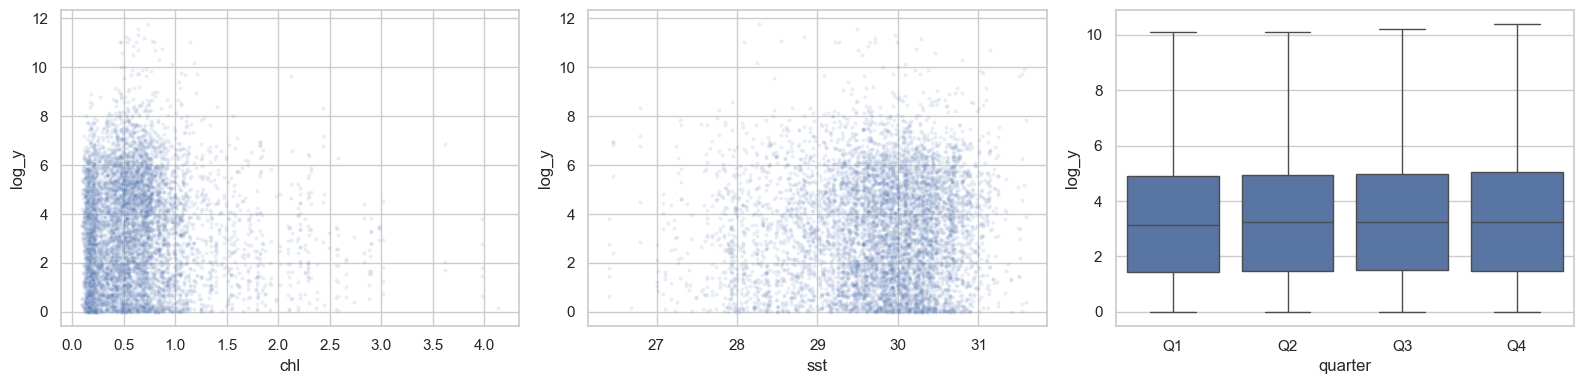

Bivariate series-clustered tests meet BH q < 0.05 for: sst, year, province, species, quarter. These are marginal associations; differences in species, province and time composition can explain them. Rank correlation and omnibus tests do not establish causation or identify which category pairs differ.

**Scatter plots:** broad vertical spread means similar environmental conditions can accompany very different yields. These pooled plots combine species and provinces, so they cannot isolate environmental effects. **Quarter box plots:** compare median lines and box overlap; quarter differences can also reflect species mix and reporting coverage.

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sample = observed_data.sample(min(7000, len(observed_data)), random_state=SEED)
for ax, x in zip(axes[:2], ['chl', 'sst']):
    sns.scatterplot(data=sample, x=x, y='log_y', alpha=0.12, s=8, ax=ax)
sns.boxplot(
    data=observed_data,
    x='quarter',
    y='log_y',
    order=['Q1', 'Q2', 'Q3', 'Q4'],
    showfliers=False,
    ax=axes[2],
)
plt.tight_layout()
plt.show()
sig = biv.loc[biv.q_BH < ALPHA, 'predictor'].tolist()
interpret(f"Bivariate series-clustered tests meet BH q < {ALPHA} for: {', '.join(sig) or 'none'}. These are marginal associations; differences in species, province and time composition can explain them. Rank correlation and omnibus tests do not establish causation or identify which category pairs differ.")
interpret('**Scatter plots:** broad vertical spread means similar environmental conditions can accompany very different yields. '
          'These pooled plots combine species and provinces, so they cannot isolate environmental effects. '
          '**Quarter box plots:** compare median lines and box overlap; quarter differences can also reflect species mix and reporting coverage.')

### 4.3 Multivariate analysis: predictors considered together
**Recorded yields only.** Model log(1 + yield) using chlorophyll, sea temperature, species, province, quarter and a linear year trend. `C(...)` marks categorical predictors. Standardized environmental predictors use one standard deviation as the unit.

Two-way clustered standard errors allow repeated province-species measurements and shared time shocks. A province-clustered model checks sensitivity to dependence across species in the same province. These corrections do not remove missingness bias or establish causation.

The model assumes common linear environmental slopes. Read confidence intervals together with the joint environmental test. Category coefficients compare groups with a reference category; omnibus tests ask whether a category's coefficients are jointly zero.

**Adjusted coefficient table:** beta is a change in log(1 + yield), holding included variables fixed. Confidence intervals spanning zero do not provide clear evidence of a nonzero slope. Category coefficients compare each level with its omitted reference group.

,beta,SE_two_way,CI_low,CI_high,p,p_province_cluster,pct_change_1plus_yield
Intercept,1.771091,0.276851,1.221472,2.320710,5.927632e-09,6.589878e-07,487.726163
C(quarter)[T.Q2],0.012578,0.035498,-0.057894,0.083049,7.238789e-01,7.737660e-01,1.265721
C(quarter)[T.Q3],0.009819,0.040250,-0.070087,0.089726,8.077912e-01,8.295668e-01,0.986763
C(quarter)[T.Q4],0.041748,0.038461,-0.034606,0.118102,2.804586e-01,2.791078e-01,4.263167
C(province)[T.Basilan],0.336859,0.253428,-0.166260,0.839978,1.869634e-01,8.140385e-04,40.054102
...,...,...,...,...,...,...,...
C(species)[T.White Shrimp],-0.177461,0.333407,-0.839357,0.484435,5.957845e-01,6.550714e-01,-16.260645
C(species)[T.Yellowfin Tuna],2.605577,0.356258,1.898315,3.312840,8.169247e-11,2.494529e-07,1253.904169
chl_z,0.001025,0.017662,-0.034038,0.036088,9.538503e-01,9.664337e-01,0.102535
sst_z,0.014670,0.014615,-0.014345,0.043685,3.180615e-01,2.857374e-01,1.477795


,term,F,p,status,q_BH
0,environment,0.533673,5.881948e-01,estimable,6.740994e-01
1,year,36.153532,3.372872e-08,estimable,5.621453e-08
2,quarter,0.513287,6.740994e-01,estimable,6.740994e-01
3,province,46.393600,1.015420e-41,estimable,2.538549e-41
4,species,34.704347,1.952348e-45,estimable,9.761738e-45


**Joint tests:** environmental p = 0.588, q = 0.674. This tests chlorophyll and temperature together after adjustment. Small group-test q-values indicate differences among category levels, not which pairs differ.

,beta,SE_two_way,CI_low,CI_high,p,p_province_cluster,pct_change_1plus_yield,q_BH
chl_z,0.001025,0.017662,-0.034038,0.036088,9.538503e-01,0.966434,0.102535,9.538503e-01
sst_z,0.014670,0.014615,-0.014345,0.043685,3.180615e-01,0.285737,1.477795,4.770923e-01
year_c,-0.017757,0.002953,-0.023620,-0.011894,3.372872e-08,0.010282,-1.760038,1.011862e-07


,term,VIF
0,chl_z,2.727485
1,sst_z,3.609811
2,year_c,1.236538


**Predictor overlap:** maximum VIF among the environmental and year terms is 3.61. A VIF near 1 means little inflation from overlap; larger values imply less precise individual slope estimates.

Observed log-yield model R² = 0.546; n = 89,446. Breusch–Pagan nominal LM p = 0; this is a residual diagnostic with iid assumptions, not the basis for clustered inference.

**chl_z:** beta 0.001, 95% cluster CI [-0.034, 0.036], BH q=0.954; province-cluster sensitivity p=0.966. An increment of one environmental SD (or one year for year_c) corresponds to 0.1% change in modeled geometric (1+yield), conditional on other variables. This is not a percent change in arithmetic mean yield.

**sst_z:** beta 0.015, 95% cluster CI [-0.014, 0.044], BH q=0.477; province-cluster sensitivity p=0.286. An increment of one environmental SD (or one year for year_c) corresponds to 1.5% change in modeled geometric (1+yield), conditional on other variables. This is not a percent change in arithmetic mean yield.

**year_c:** beta -0.018, 95% cluster CI [-0.024, -0.012], BH q=1.01e-07; province-cluster sensitivity p=0.0103. An increment of one environmental SD (or one year for year_c) corresponds to -1.8% change in modeled geometric (1+yield), conditional on other variables. This is not a percent change in arithmetic mean yield.

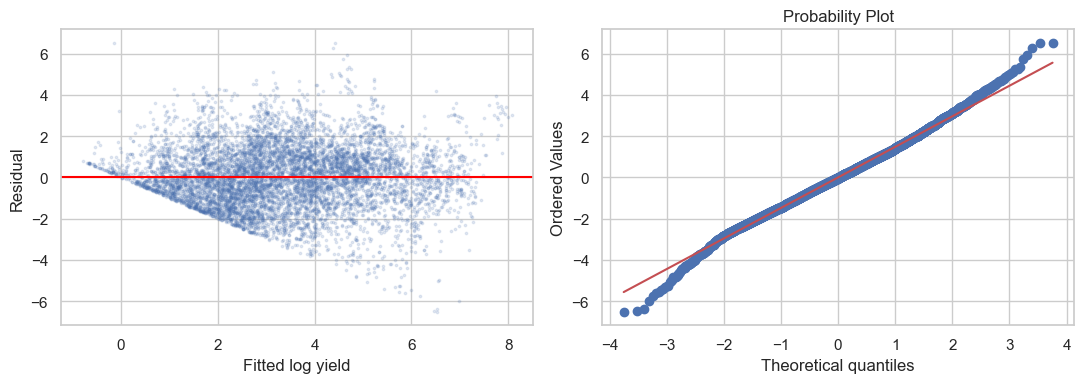

**Residual-versus-fitted plot:** the uneven, fan-like spread indicates that prediction errors do not have constant variance. **Residual Q-Q plot:** tail departures show imperfect normality. Clustered standard errors address dependence in inference, but do not fix a poorly specified model or missingness bias.

In [15]:
for x in ['chl', 'sst']:
    mu = environmental_data[x].mean()
    sd = environmental_data[x].std()
    data[x + '_z'] = (data[x] - mu) / sd
data['year_c'] = data.year - data.year.mean()
observed_data = data[data[TARGET].notna()].copy()
observed_data['log_y'] = np.log1p(observed_data[TARGET])
FORMULA = 'log_y ~ chl_z + sst_z + year_c + C(quarter) + C(province) + C(species)'
groups = np.column_stack([pd.factorize(observed_data.series)[0], pd.factorize(observed_data.time)[0]])
fit = smf.ols(FORMULA, observed_data).fit(cov_type='cluster', cov_kwds={'groups': groups}, use_t=True)
spatial = smf.ols(FORMULA, observed_data).fit(
    cov_type='cluster',
    cov_kwds={'groups': observed_data.province},
    use_t=True,
)
ci = fit.conf_int()
coef = pd.DataFrame({
    'beta': fit.params,
    'SE_two_way': fit.bse,
    'CI_low': ci[0],
    'CI_high': ci[1],
    'p': fit.pvalues,
    'p_province_cluster': spatial.pvalues,
})
coef['pct_change_1plus_yield'] = 100 * np.expm1(coef.beta)
interpret('**Adjusted coefficient table:** beta is a change in log(1 + yield), holding included variables fixed. '
          'Confidence intervals spanning zero do not provide clear evidence of a nonzero slope. '
          'Category coefficients compare each level with its omitted reference group.')
display(coef)

def safe_wald(model, names):
    R = np.eye(len(model.params))[[list(model.params.index).index(x) for x in names]]
    cov = R @ model.cov_params().to_numpy() @ R.T
    if np.linalg.matrix_rank(cov) < len(names) or np.linalg.eigvalsh(cov).min() <= 0:
        return dict(F=np.nan, p=np.nan, status='not estimable: singular/indefinite cluster covariance')
    result = model.wald_test(R, scalar=True)
    return dict(F=float(result.statistic), p=float(result.pvalue), status='estimable')
tests = []
for term, names in [
    ('environment', ['chl_z', 'sst_z']),
    ('year', ['year_c']),
    ('quarter', [x for x in fit.params.index if x.startswith('C(quarter)')]),
    ('province', [x for x in fit.params.index if x.startswith('C(province)')]),
    ('species', [x for x in fit.params.index if x.startswith('C(species)')]),
]:
    tests.append(dict(term=term, **safe_wald(fit, names)))
multi = adjust_pvalues(pd.DataFrame(tests))
display(multi)
environment_row = multi.set_index('term').loc['environment']
interpret(f'**Joint tests:** environmental p = {environment_row.p:.3g}, q = {environment_row.q_BH:.3g}. '
          'This tests chlorophyll and temperature together after adjustment. '
          'Small group-test q-values indicate differences among category levels, not which pairs differ.')
focus = adjust_pvalues(coef.loc[['chl_z', 'sst_z', 'year_c']].copy())
display(focus)
X = fit.model.exog
vif = pd.DataFrame([{
    'term': fit.model.exog_names[i],
    'VIF': variance_inflation_factor(X, i),
} for i in range(1, len(fit.params)) if fit.model.exog_names[i] in ['chl_z', 'sst_z', 'year_c']])
display(vif)
interpret(f'**Predictor overlap:** maximum VIF among the environmental and year terms is {vif.VIF.max():.2f}. '
          'A VIF near 1 means little inflation from overlap; larger values imply less precise individual slope estimates.')
bp = het_breuschpagan(fit.resid, fit.model.exog)
interpret(f'Observed log-yield model R² = {fit.rsquared:.3f}; n = {int(fit.nobs):,}. Breusch–Pagan nominal LM p = {bp[1]:.3g}; this is a residual diagnostic with iid assumptions, not the basis for clustered inference.')
for term in ['chl_z', 'sst_z', 'year_c']:
    r = focus.loc[term]
    interpret(f'**{term}:** beta {r.beta:.3f}, 95% cluster CI [{r.CI_low:.3f}, {r.CI_high:.3f}], BH q={r.q_BH:.3g}; province-cluster sensitivity p={r.p_province_cluster:.3g}. An increment of one environmental SD (or one year for year_c) corresponds to {100 * np.expm1(r.beta):.1f}% change in modeled geometric (1+yield), conditional on other variables. This is not a percent change in arithmetic mean yield.')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
idx = np.random.default_rng(SEED).choice(
    len(observed_data),
    min(8000, len(observed_data)),
    replace=False,
)
axes[0].scatter(fit.fittedvalues.iloc[idx], fit.resid.iloc[idx], s=3, alpha=0.15)
axes[0].axhline(0, color='red')
axes[0].set(xlabel='Fitted log yield', ylabel='Residual')
stats.probplot(fit.resid.iloc[idx], plot=axes[1])
plt.tight_layout()
plt.show()
interpret('**Residual-versus-fitted plot:** the uneven, fan-like spread indicates that prediction errors do not have constant variance. '
          '**Residual Q-Q plot:** tail departures show imperfect normality. '
          'Clustered standard errors address dependence in inference, but do not fix a poorly specified model or missingness bias.')

## 5. Group-mean imputation
Group mean performed best in the earlier comparison of simple candidates. This final notebook keeps only the selected method and validates its accuracy.

**Example:** for missing CDO sardine yield in 2004 Q3, average recorded 2004 Q1, Q2 and Q4 yields. Require at least two recorded values in a group.

Use this order when the first group lacks enough values:
1. Same province, species and year: other quarters.
2. Same province, species and quarter: other years.
3. Same province and species: all dates.
4. Same species: all provinces and dates.
5. Overall recorded mean if no earlier group has two values.

Means use recorded yields only, never previously filled values. Combinations with no recorded yield remain blank in the completed-yield column. Their separate suggestions are not treated as reliable completed yields.

**Validation:** hide 20% of known yields at random and, separately, four consecutive quarters per combination. Repeat each pattern three times. Calculate means after hiding these values. This evaluates historical filling, not forecasting.

MAE measures average error in metric tons; RMSE emphasizes large errors. RMSLE measures log-scale error; it is an evaluation metric, not log imputation. Total bias checks predicted totals; the log-spread ratio checks distribution spread. These internal checks do not prove that estimates for unreported yields are unbiased.

Filling creates a separate `completed` dataset. It does not change the recorded-data EDA above.

### 5.1 Reusable functions

In [16]:
def group_mean_predictions(train, target):
    """Try specific groups first, using at least two observations per group."""
    predictions = pd.Series(np.nan, index=target.index)
    groups = [['province', 'species', 'year'], ['province', 'species', 'quarter'], ['province', 'species'], ['species']]
    for columns in groups:
        summary = train.groupby(columns)[TARGET].agg(mean='mean', count='count')
        means = summary['mean'].where(summary['count'] >= 2)
        means.name = 'group_prediction'
        available = target.join(means, on=columns)['group_prediction']
        predictions = predictions.fillna(available)
    return predictions.fillna(train[TARGET].mean()).to_numpy()

def make_validation_mask(frame, scenario, rng):
    if scenario == 'scattered':
        return rng.random(len(frame)) < 0.2
    starts = {series: rng.integers(data.time.min(), data.time.max() - 2) for series in frame.series.unique()}
    start = frame.series.map(starts)
    return ((frame.time >= start) & (frame.time < start + 4)).to_numpy()

def prediction_metrics(actual, predicted):
    return {'MAE': np.mean(np.abs(actual - predicted)), 'RMSE': np.sqrt(np.mean((actual - predicted) ** 2)), 'RMSLE': np.sqrt(np.mean((np.log1p(actual) - np.log1p(predicted)) ** 2)), 'total_bias_pct': 100 * (predicted.sum() / actual.sum() - 1), 'log_spread_ratio': np.std(np.log1p(predicted)) / np.std(np.log1p(actual))}

### 5.2 Validate the selected method
Test the group-mean rules on scattered and consecutive gaps. Lower errors are better. Trial results remain in `scores`; summary tables are displayed below.

In [17]:
records = []
for scenario in ['scattered', 'block']:
    for repeat in range(REPEATS):
        hidden = make_validation_mask(
            observed_data, scenario, np.random.default_rng(SEED + repeat)
        )
        train = observed_data.loc[~hidden]
        test = observed_data.loc[hidden]
        predicted = group_mean_predictions(train, test)
        actual = test[TARGET].to_numpy()
        records.append({
            'scenario': scenario, 'repeat': repeat,
            **prediction_metrics(actual, predicted),
        })

scores = pd.DataFrame(records)
metrics = ['MAE', 'RMSE', 'RMSLE', 'total_bias_pct', 'log_spread_ratio']
validation_summary = scores[metrics].mean()
display(validation_summary.to_frame('Group mean: average across trials').round(3))
display(scores.groupby('scenario')[metrics].mean().round(3))
best_method = 'group_mean'
interpret(
    f'**Validation:** MAE = {validation_summary.MAE:,.1f} metric tons; '
    f'total bias = {validation_summary.total_bias_pct:+.1f}%; '
    f'log-spread ratio = {validation_summary.log_spread_ratio:.2f}. '
    'Low total bias can coexist with large individual errors.'
)
interpret(
    '**Gap patterns:** compare scattered and block results. If a full year is hidden, '
    'same-year means cannot be used, so validation also checks the fallback groups. '
    'A spread ratio below 1 indicates less variation in filled values than recorded yields.'
)

,Group mean: average across trials
MAE,189.618
RMSE,1581.406
RMSLE,0.980
total_bias_pct,0.637
log_spread_ratio,0.955


,MAE,RMSE,RMSLE,total_bias_pct,log_spread_ratio
scenario,,,,,
block,189.615,1379.903,1.05,0.979,0.943
scattered,189.622,1782.909,0.91,0.295,0.966


**Validation:** MAE = 189.6 metric tons; total bias = +0.6%; log-spread ratio = 0.95. Low total bias can coexist with large individual errors.

**Gap patterns:** compare scattered and block results. If a full year is hidden, same-year means cannot be used, so validation also checks the fallback groups. A spread ratio below 1 indicates less variation in filled values than recorded yields.

### 5.3 Fill gaps and export
Keep original measurements and flag filled values. This is the only cell that writes an output file.

In [18]:
missing_rows = data[data.missing.eq(1)]
suggestions = group_mean_predictions(observed_data, missing_rows)
completed = source_data.copy()
completed['yield_model_suggestion'] = np.nan
completed.loc[missing_rows.index, 'yield_model_suggestion'] = suggestions
completed['yield_completed'] = data[TARGET].copy()
eligible = data.missing.eq(1) & ((data.series_observed_n > 0) | ALLOW_ALL_MISSING_SERIES)
completed.loc[eligible, 'yield_completed'] = completed.loc[eligible, 'yield_model_suggestion']
completed['yield_was_imputed'] = eligible
completed['yield_status'] = np.where(
    data.missing.eq(0),
    'observed',
    np.where(eligible, 'imputed', 'unresolved_no_observed_series'),
)
completed['imputation_method'] = np.where(eligible, best_method, '')
assert completed.loc[data.missing.eq(0), 'yield_completed'].equals(data.loc[data.missing.eq(0), TARGET])
assert completed.loc[eligible, 'yield_completed'].ge(0).all()
OUTPUT_DIR.mkdir(exist_ok=True)
completed.to_csv(OUTPUT_DIR / 'blueshift_yield_completed.csv', index=False)
interpret(f'Filled {eligible.sum():,} missing entries; left {completed.yield_completed.isna().sum():,} unresolved. The suggestion column also holds estimates for combinations with no recorded yield, but those are extrapolations outside within-series validation support. Single imputation does not preserve residual variance or quantify missing-value uncertainty; do not treat completed values as measured outcomes for hypothesis tests.')

# Show how often the user's same-year rule has enough observed quarters.
if best_method == 'group_mean':
    same_year_counts = data.groupby(['province', 'species', 'year'])[TARGET].transform('count')
    same_year_fills = (eligible & same_year_counts.ge(2)).sum()
    fallback_fills = eligible.sum() - same_year_fills
    interpret(
        f'**Which means were used?** {same_year_fills:,} fills '
        f'({same_year_fills / eligible.sum():.1%}) can use the same-year quarterly mean. '
        f'The other {fallback_fills:,} require the documented fallback groups. '
        'The recommendation therefore applies to the complete group-mean hierarchy, '
        'not just averaging the other quarters of the same year.'
    )


Filled 42,170 missing entries; left 20,448 unresolved. The suggestion column also holds estimates for combinations with no recorded yield, but those are extrapolations outside within-series validation support. Single imputation does not preserve residual variance or quantify missing-value uncertainty; do not treat completed values as measured outcomes for hypothesis tests.

**Which means were used?** 3,648 fills (8.7%) can use the same-year quarterly mean. The other 38,522 require the documented fallback groups. The recommendation therefore applies to the complete group-mean hierarchy, not just averaging the other quarters of the same year.

## 6. After-imputation comparison: recorded versus completed data
**This section uses estimated yields.** It is separate from the recorded-data EDA. Compare model coefficients before and after filling, then decrease or increase only filled values by 25%.

The scenarios are assumptions, not confidence intervals. Filled values are not new measurements, so they are not used to claim stronger statistical evidence. Annual totals exclude combinations still left blank. The first and last years have only part-year coverage, so their totals are not directly comparable with full years.

,scenario,n,chl_z,sst_z,year_c
0,observed_only,89446,0.001025,0.014670,-0.017757
1,completed,131616,0.001495,0.012599,-0.013302
2,imputed_minus25,131616,0.000817,0.014279,-0.012393
3,imputed_plus25,131616,0.002002,0.011201,-0.014025


**chl_z:** coefficient changes from 0.0010 using recorded yields to 0.0015 after filling. These are changes in point estimates, not new significance tests.

**sst_z:** coefficient changes from 0.0147 using recorded yields to 0.0126 after filling. These are changes in point estimates, not new significance tests.

**year_c:** coefficient changes from -0.0178 using recorded yields to -0.0133 after filling. These are changes in point estimates, not new significance tests.

,observed_sum,completed_partial_sum,unresolved_rows
year,,,
2002,569851.28,6.412789e+05,426
2003,1273936.44,1.399104e+06,852
2004,1450079.23,1.561989e+06,852
2005,1489410.66,1.591775e+06,852
2006,1590988.16,1.692698e+06,852
2007,1712904.57,1.815129e+06,852
2008,1824713.80,1.926482e+06,852
2009,1827772.42,1.928700e+06,852
2010,1871520.73,1.972694e+06,852


**Annual totals table:** 20,448 yields remain unfilled across all years. The completed total adds eligible estimates to recorded production, but is still incomplete. The difference between columns is estimated yield, not measured production growth.

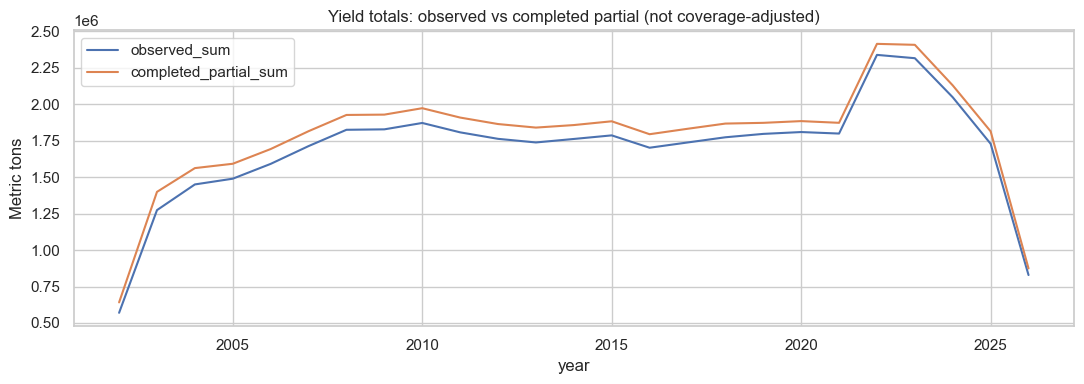

**Practical conclusion:** use the validation winner for eligible retrospective gaps, retain provenance flags, and resolve the meaning of never-reported combinations before completing them. Use observed-data clustered estimates as conditional associations; inspect coefficient sensitivity before drawing substantive conclusions. Neither single imputation nor strong predictive performance establishes MAR, causal environmental effects, or complete population totals.

**Annual trend plot:** the gap between lines is the amount added by imputation. A larger completed total is expected when nonnegative estimates replace blanks. It does not prove that production increased. Partial boundary years, reporting changes and unresolved yields limit trend comparisons.

In [19]:
sensitivity = []
for label, factor in [
    ('observed_only', None),
    ('completed', 1),
    ('imputed_minus25', 0.75),
    ('imputed_plus25', 1.25),
]:
    if factor is None:
        model = fit
    else:
        temp = data.copy()
        temp[TARGET] = completed.yield_completed
        temp.loc[eligible, TARGET] *= factor
        temp = temp[temp[TARGET].notna()].copy()
        temp['log_y'] = np.log1p(temp[TARGET])
        model = smf.ols(FORMULA, temp).fit()
    sensitivity.append(dict(
        scenario=label,
        n=int(model.nobs),
        **model.params[['chl_z', 'sst_z', 'year_c']].to_dict(),
    ))
sensitivity_table = pd.DataFrame(sensitivity)
display(sensitivity_table)
recorded_coefficients = sensitivity_table.set_index('scenario').loc['observed_only']
completed_coefficients = sensitivity_table.set_index('scenario').loc['completed']
for term in ['chl_z', 'sst_z', 'year_c']:
    interpret(f'**{term}:** coefficient changes from {recorded_coefficients[term]:.4f} using recorded yields '
              f'to {completed_coefficients[term]:.4f} after filling. '
              'These are changes in point estimates, not new significance tests.')
annual = pd.DataFrame({
    'year': data.year,
    'observed': data[TARGET],
    'completed_partial': completed.yield_completed,
    'unresolved': completed.yield_completed.isna().astype(int),
}).groupby('year').agg(observed_sum=('observed', 'sum'), completed_partial_sum=('completed_partial', 'sum'), unresolved_rows=('unresolved', 'sum'))
display(annual)
interpret(f'**Annual totals table:** {annual.unresolved_rows.sum():,} yields remain unfilled across all years. '
          'The completed total adds eligible estimates to recorded production, but is still incomplete. '
          'The difference between columns is estimated yield, not measured production growth.')
annual[['observed_sum', 'completed_partial_sum']].plot(
    figsize=(11, 4),
    title='Yield totals: observed vs completed partial (not coverage-adjusted)',
)
plt.ylabel('Metric tons')
plt.tight_layout()
plt.show()
interpret('**Practical conclusion:** use the validation winner for eligible retrospective gaps, retain provenance flags, and resolve the meaning of never-reported combinations before completing them. Use observed-data clustered estimates as conditional associations; inspect coefficient sensitivity before drawing substantive conclusions. Neither single imputation nor strong predictive performance establishes MAR, causal environmental effects, or complete population totals.')
interpret('**Annual trend plot:** the gap between lines is the amount added by imputation. '
          'A larger completed total is expected when nonnegative estimates replace blanks. '
          'It does not prove that production increased. Partial boundary years, reporting changes and unresolved yields limit trend comparisons.')

## 7. Main findings and limits

In [20]:
interpret(
    f'**Imputation:** group mean is the selected method. '
    f'Mean validation MAE = {validation_summary.MAE:,.1f} metric tons; '
    f'total bias = {validation_summary.total_bias_pct:+.1f}%. '
    'The completed-data CSV uses only the documented group-mean hierarchy.'
)

environment_test = multi.set_index('term').loc['environment']
interpret(
    f'**Adjusted environmental association:** joint test p = {environment_test.p:.3g}. '
    'This model does not provide sufficient evidence for common linear environmental slopes. '
    'It does not rule out nonlinear or species-specific relationships.'
)
year_result = focus.loc['year_c']
interpret(
    f'**Time trend:** year coefficient = {year_result.beta:.3f}, '
    f'95% clustered CI [{year_result.CI_low:.3f}, {year_result.CI_high:.3f}]. '
    'This is an adjusted association in observed log yield, not a causal effect.'
)
interpret(
    f'**Coverage:** {completed.yield_was_imputed.sum():,} yields were filled; '
    f'{completed.yield_completed.isna().sum():,} remain unresolved. '
    'Annual totals exclude yields that remain blank. Missingness and imperfect model fit limit generalization. '
    'Single imputation does not account for all missing-value uncertainty. '
    'Hypothesis tests use recorded yields only.'
)

**Imputation:** group mean is the selected method. Mean validation MAE = 189.6 metric tons; total bias = +0.6%. The completed-data CSV uses only the documented group-mean hierarchy.

**Adjusted environmental association:** joint test p = 0.588. This model does not provide sufficient evidence for common linear environmental slopes. It does not rule out nonlinear or species-specific relationships.

**Time trend:** year coefficient = -0.018, 95% clustered CI [-0.024, -0.012]. This is an adjusted association in observed log yield, not a causal effect.

**Coverage:** 42,170 yields were filled; 20,448 remain unresolved. Annual totals exclude yields that remain blank. Missingness and imperfect model fit limit generalization. Single imputation does not account for all missing-value uncertainty. Hypothesis tests use recorded yields only.

## Reuse and references
Change the settings in Section 1 and run all cells in order. Only `analysis_outputs/blueshift_yield_completed.csv` is exported.

The completed CSV keeps original columns and adds completed yield, imputation flag, status, method and separate model suggestions. Combinations with no recorded yield remain unresolved by default.

References: [avoiding leakage](https://scikit-learn.org/stable/common_pitfalls.html), [time-dependent validation](https://scikit-learn.org/stable/modules/cross_validation.html), [joint coefficient tests](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.wald_test_terms.html).